# Precipitação e gravidade dos acidentes em rodovias federais de São Paulo

**ACH0042 — Resolução de Problemas II, USP/EACH**  
Gustavo Henrique Ferreira Alves, Gustavo Lima de Souza e Guilherme Padun Santos

O estudo avalia a associação entre a precipitação registrada por estações do INMET e a gravidade dos acidentes da PRF. As bases da PRF contêm uma linha por ocorrência e cobrem 2025 completo e janeiro a maio de 2026.

O desfecho tem três níveis ordenados — sem vítimas, com vítimas feridas e com vítimas fatais. A exposição é apresentada em duas escalas — precipitação horária em milímetros e presença de precipitação acima de zero.

## 1. Dados produzidos pelo pipeline

Execute `python executar_pipeline.py` na raiz do projeto para gerar os CSVs seguindo o [README](README.md). Este notebook lê esses arquivos e apresenta resumos descritivos e estimativas já calculadas.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, MultipleLocator, PercentFormatter
import pandas as pd
from IPython.display import Markdown, display

from src.config import LIMITE_DISTANCIA_KM, LIMITE_TEMPO_MIN, PASTA_DADOS_PROCESSADOS

arquivos = {
    "prf": "acidentes_sp.csv",
    "inmet": "inmet_sp.csv",
    "integrada": "base_integrada.csv",
    "amostra": "base_modelagem.csv",
    "ordinal": "resultados_regressao_ordinal.csv",
    "multinomial": "resultados_regressao_multinomial.csv",
    "sensibilidade": "sensibilidade_distancia.csv",
    "ausencia": "diagnostico_ausencia_precipitacao.csv",
}
caminhos = {chave: PASTA_DADOS_PROCESSADOS / nome for chave, nome in arquivos.items()}
faltantes = [caminho.name for caminho in caminhos.values() if not caminho.is_file()]
if faltantes:
    raise FileNotFoundError(
        f"CSVs ausentes em datasets/processed/: {', '.join(faltantes)}. "
        "Execute python executar_pipeline.py na raiz do projeto."
    )

prf = pd.read_csv(caminhos["prf"], usecols=["ano", "data_inversa"], parse_dates=["data_inversa"])
inmet = pd.read_csv(caminhos["inmet"], usecols=["codigo_wmo"], dtype={"codigo_wmo": "string"})
integrada = pd.read_csv(
    caminhos["integrada"],
    usecols=["ano", "precipitacao_mm", "distancia_estacao_km", "diferenca_tempo_min"],
)
amostra = pd.read_csv(
    caminhos["amostra"],
    usecols=["classificacao_acidente", "precipitacao_mm", "chuva_binaria"],
)
ordinal = pd.read_csv(caminhos["ordinal"])
multinomial = pd.read_csv(caminhos["multinomial"])
sensibilidade = pd.read_csv(caminhos["sensibilidade"])
ausencia = pd.read_csv(caminhos["ausencia"], index_col=0)

In [2]:
AZUL = "#174A73"
VERDE = "#187875"
CINZA = "#596875"
GRADE = "#DDE5EC"
ROXO = "#67448B"
TEXTO = "#182E3E"

plt.rcParams.update({
    "font.size": 11,
    "text.color": TEXTO,
    "axes.labelcolor": TEXTO,
    "axes.titlecolor": TEXTO,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": CINZA,
    "xtick.color": TEXTO,
    "ytick.color": TEXTO,
    "grid.color": GRADE,
    "axes.axisbelow": True,
    "legend.frameon": False,
    "figure.dpi": 105,
})


def inteiro(valor):
    return f"{valor:,.0f}".replace(",", ".")


def decimal(valor, casas=1):
    return f"{valor:.{casas}f}".replace(".", ",")


def exibir_estimativas(dados, rotulos, casas=4):
    tabela = dados[list(rotulos)].rename(columns=rotulos).copy()
    tabela["OR"] = dados["odds_ratio"].map(lambda valor: decimal(valor, casas))
    tabela["IC95%"] = [
        f"{decimal(inferior, casas)} a {decimal(superior, casas)}"
        for inferior, superior in zip(dados["ic_95_inf"], dados["ic_95_sup"])
    ]
    tabela["p"] = dados["p_valor"].map(lambda valor: decimal(valor, casas))
    display(tabela.reset_index(drop=True))

## 2. Cobertura e seleção da amostra

As bases de preparação informam o volume disponível antes da modelagem. As datas abaixo mostram a cobertura observada da PRF em cada período. Como os períodos têm durações diferentes, as contagens servem para descrever a cobertura.

In [3]:
periodos = prf.groupby("ano").agg(
    início=("data_inversa", "min"),
    fim=("data_inversa", "max"),
    acidentes=("data_inversa", "size"),
)
validos_por_ano = integrada.groupby("ano")["precipitacao_mm"].count()
cobertura = pd.DataFrame({
    "Início": periodos["início"].dt.strftime("%d/%m/%Y"),
    "Fim": periodos["fim"].dt.strftime("%d/%m/%Y"),
    "Acidentes PRF": periodos["acidentes"].map(inteiro),
    "Precipitação disponível": validos_por_ano.map(inteiro),
    "Disponibilidade": (validos_por_ano / periodos["acidentes"]).map(
        lambda valor: f"{decimal(valor * 100)}%"
    ),
})
cobertura.index.name = "Ano"

display(Markdown(
    f"**PRF:** {inteiro(len(prf))} acidentes. "
    f"**INMET:** {inteiro(len(inmet))} registros horários de "
    f"{inteiro(inmet['codigo_wmo'].nunique())} estações."
))
display(cobertura)

**PRF:** 6.515 acidentes. **INMET:** 583.680 registros horários de 40 estações.

,Início,Fim,Acidentes PRF,Precipitação disponível,Disponibilidade
Ano,,,,,
2025,01/01/2025,31/12/2025,4.683,3.982,"85,0%"
2026,01/01/2026,31/05/2026,1.832,1.679,"91,6%"


A etapa de integração associa cada acidente à estação mais próxima e, nessa estação, à medição mais próxima no tempo. A última linha do fluxo é o tamanho da base de modelagem exportada. Ela incorpora os critérios espaciais, temporais e de completude usados pelo pipeline.

In [4]:
n_integrada = len(integrada)
n_disponivel = integrada["precipitacao_mm"].count()
n_ausente = n_integrada - n_disponivel
n_amostra = len(amostra)

fluxo = pd.DataFrame({
    "Etapa": [
        "Base integrada",
        "Com precipitação disponível",
        f"Amostra principal (até {LIMITE_DISTANCIA_KM} km)",
    ],
    "Acidentes": [n_integrada, n_disponivel, n_amostra],
    "Excluídos na etapa": ["—", inteiro(n_ausente), inteiro(n_disponivel - n_amostra)],
})
fluxo["% da base integrada"] = fluxo["Acidentes"].map(
    lambda n: f"{decimal(n / n_integrada * 100, 2)}%"
)
fluxo["Acidentes"] = fluxo["Acidentes"].map(inteiro)
display(fluxo)

display(Markdown(
    f"**Precipitação ausente:** {inteiro(n_ausente)} acidentes "
    f"({decimal(100 * n_ausente / n_integrada, 2)}%). "
    "Os registros com 0 mm fazem parte da categoria de precipitação disponível."
))

,Etapa,Acidentes,Excluídos na etapa,% da base integrada
0,Base integrada,6.515,—,"100,00%"
1,Com precipitação disponível,5.661,854,"86,89%"
2,Amostra principal (até 30 km),3.730,1.931,"57,25%"


**Precipitação ausente:** 854 acidentes (13,11%). Os registros com 0 mm fazem parte da categoria de precipitação disponível.

## 3. Qualidade do pareamento

Para avaliar a cobertura espacial, a curva mostra a proporção acumulada de acidentes à medida que o limite de distância aumenta. O denominador é a base integrada com distância registrada, incluindo acidentes sem medição de precipitação. Os percentuais da curva descrevem o pareamento em si. Os tamanhos das amostras que entram nos modelos aparecem na seção de sensibilidade.

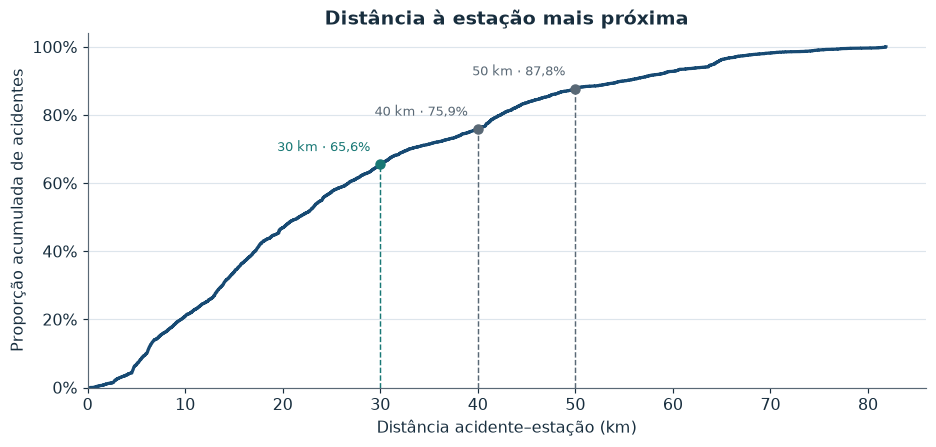

A distância mediana foi **21,7 km**. A diferença temporal mediana foi **15 min** e a máxima, **30 min**, diante do limite de 60 min usado no pipeline.

In [5]:
distancia = integrada["distancia_estacao_km"].dropna()
tempo = integrada["diferenca_tempo_min"].dropna()
limites = sorted(sensibilidade["limite_km"].unique())

fig, ax = plt.subplots(figsize=(8.8, 4.15), layout="constrained")
ax.ecdf(distancia, color=AZUL, linewidth=2.2)
for limite in limites:
    proporcao = distancia.le(limite).mean()
    cor = VERDE if limite == LIMITE_DISTANCIA_KM else CINZA
    ax.vlines(limite, 0, proporcao, color=cor, linestyle="--", linewidth=1)
    ax.scatter(limite, proporcao, color=cor, s=38, zorder=3)
    ax.annotate(
        f"{inteiro(limite)} km · {decimal(proporcao * 100)}%",
        (limite, proporcao),
        xytext=(-7, 9),
        ha="right",
        textcoords="offset points",
        color=cor,
        fontsize=9,
    )

ax.set(
    title="Distância à estação mais próxima",
    xlabel="Distância acidente–estação (km)",
    ylabel="Proporção acumulada de acidentes",
    xlim=(0, None),
    ylim=(0, 1.04),
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y")
plt.show()

display(Markdown(
    f"A distância mediana foi **{decimal(distancia.median())} km**. "
    f"A diferença temporal mediana foi **{inteiro(tempo.median())} min** e "
    f"a máxima, **{inteiro(tempo.max())} min**, diante do limite de "
    f"{inteiro(LIMITE_TEMPO_MIN)} min usado no pipeline."
))

## 4. Precipitação e gravidade na amostra principal

A composição por gravidade usa como denominador cada grupo de exposição. As contagens ajudam a interpretar diferenças percentuais quando há poucos eventos fatais. Trata-se do perfil dos acidentes registrados pela PRF na amostra principal.

A intensidade é resumida apenas entre os acidentes com precipitação positiva. A escala logarítmica no eixo horizontal acomoda a cauda à direita e mantém as medições positivas no gráfico, inclusive os valores extremos.

classificacao_acidente,Sem Vítimas,Com Vítimas Feridas,Com Vítimas Fatais,Total
Precipitação,,,,
Sem chuva,463,2.732,133,3.328
Com chuva,67,326,9,402


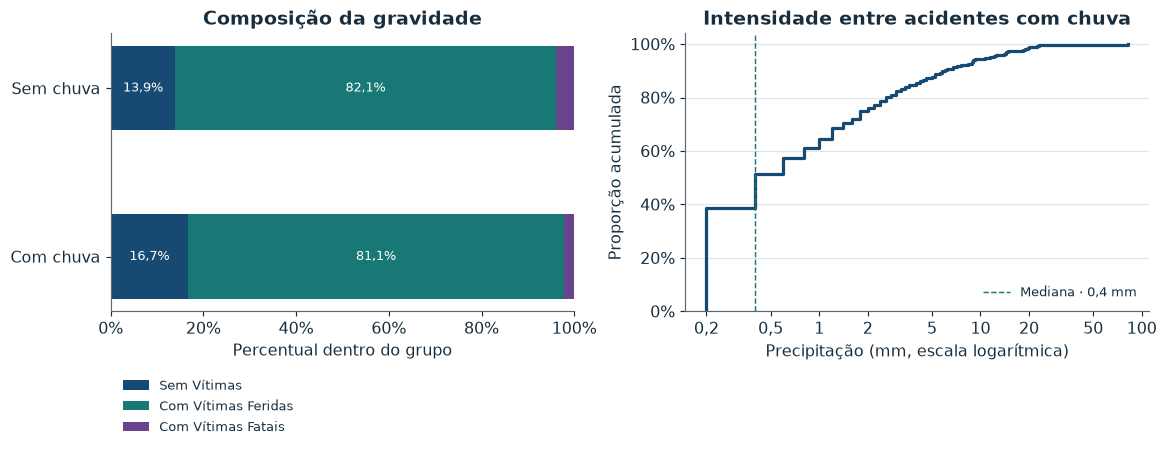

Na amostra principal, **89,2%** dos acidentes tiveram registro de 0 mm. Entre os 402 acidentes com chuva, a mediana foi **0,4 mm**, o percentil 90 foi **6,0 mm** e o máximo foi **82 mm**. Foram observados **9 acidentes fatais** no grupo com chuva (2,2% do grupo) e **133** no grupo sem chuva (4,0%).

In [6]:
gravidades = ["Sem Vítimas", "Com Vítimas Feridas", "Com Vítimas Fatais"]
grupos = ["Sem chuva", "Com chuva"]
frequencias = pd.crosstab(amostra["chuva_binaria"], amostra["classificacao_acidente"])
frequencias = frequencias.reindex(index=[0, 1], columns=gravidades, fill_value=0)
frequencias.index = pd.Index(grupos, name="Precipitação")
totais = frequencias.sum(axis=1)
composicao = frequencias.div(totais, axis=0)
positiva = amostra.loc[amostra["precipitacao_mm"].gt(0), "precipitacao_mm"]

resumo = frequencias.assign(Total=totais).map(inteiro)
display(resumo)

fig, (ax_gravidade, ax_intensidade) = plt.subplots(
    1, 2, figsize=(11, 4.15), layout="constrained"
)
acumulado = pd.Series(0.0, index=grupos)
for gravidade, cor in zip(gravidades, (AZUL, VERDE, ROXO)):
    valores = composicao[gravidade]
    ax_gravidade.barh(grupos, valores, left=acumulado, height=0.5, color=cor, label=gravidade)
    for linha, grupo in enumerate(grupos):
        if valores.loc[grupo] >= 0.08:
            ax_gravidade.text(
                acumulado.loc[grupo] + valores.loc[grupo] / 2,
                linha,
                f"{decimal(valores.loc[grupo] * 100)}%",
                ha="center",
                va="center",
                color="white",
                fontsize=9,
            )
    acumulado += valores

ax_gravidade.set(title="Composição da gravidade", xlabel="Percentual dentro do grupo", xlim=(0, 1))
ax_gravidade.xaxis.set_major_formatter(PercentFormatter(1))
ax_gravidade.invert_yaxis()
ax_gravidade.legend(loc="upper left", bbox_to_anchor=(0, -0.2), fontsize=9)

ax_intensidade.ecdf(positiva, color=AZUL, linewidth=2.2)
ax_intensidade.axvline(
    positiva.median(), color=VERDE, linestyle="--", linewidth=1,
    label=f"Mediana · {decimal(positiva.median())} mm",
)
ax_intensidade.set(
    title="Intensidade entre acidentes com chuva",
    xlabel="Precipitação (mm, escala logarítmica)",
    ylabel="Proporção acumulada",
    xscale="log",
    ylim=(0, 1.04),
)
ax_intensidade.yaxis.set_major_formatter(PercentFormatter(1))
ax_intensidade.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
ax_intensidade.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}".replace(".", ",")))
ax_intensidade.minorticks_off()
ax_intensidade.grid(axis="y")
ax_intensidade.legend(loc="lower right", fontsize=9)
plt.show()

display(Markdown(
    f"Na amostra principal, **{decimal(100 * totais['Sem chuva'] / n_amostra)}%** "
    f"dos acidentes tiveram registro de 0 mm. Entre os {inteiro(len(positiva))} acidentes "
    f"com chuva, a mediana foi **{decimal(positiva.median())} mm**, o percentil 90 foi "
    f"**{decimal(positiva.quantile(0.9))} mm** e o máximo foi **{decimal(positiva.max(), 0)} mm**. "
    f"Foram observados **{inteiro(frequencias.loc['Com chuva', 'Com Vítimas Fatais'])} "
    f"acidentes fatais** no grupo com chuva "
    f"({decimal(composicao.loc['Com chuva', 'Com Vítimas Fatais'] * 100)}% do grupo) "
    f"e **{inteiro(frequencias.loc['Sem chuva', 'Com Vítimas Fatais'])}** no grupo sem chuva "
    f"({decimal(composicao.loc['Sem chuva', 'Com Vítimas Fatais'] * 100)}%)."
))

## 5. Regressão logística ordinal

A razão de chances (OR) descreve a associação com as chances cumulativas de estar acima dos cortes da escala de gravidade. A exposição contínua representa um acréscimo de 1 mm. A exposição binária compara presença de chuva com 0 mm. O ajuste inclui fase do dia, tipo de pista, traçado da via, ano e mês.

O ponto indica a estimativa e a barra mostra o IC95%. A linha tracejada marca OR = 1. Cada painel tem sua própria escala horizontal e corresponde a uma unidade de exposição distinta.

,Exposição,Modelo,OR,IC95%,p
0,Precipitação (por 1 mm),Bruto,"0,977537","0,949680 a 1,006212","0,123520"
1,Chuva (presença vs. 0 mm),Bruto,"0,765912","0,592193 a 0,990591","0,042154"
2,Precipitação (por 1 mm),Ajustado,"0,977261","0,949118 a 1,006238","0,122871"
3,Chuva (presença vs. 0 mm),Ajustado,"0,831317","0,637730 a 1,083667","0,171971"


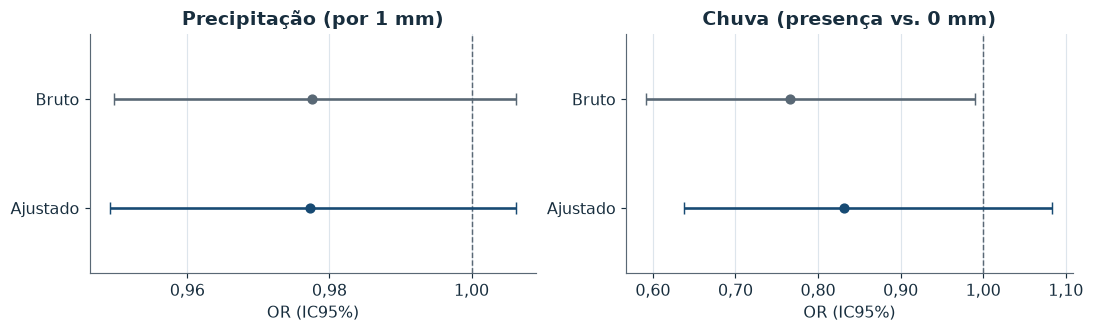

In [7]:
exposicoes = {
    "precipitacao_mm": "Precipitação (por 1 mm)",
    "chuva_binaria": "Chuva (presença vs. 0 mm)",
}
efeitos_ordinais = ordinal.loc[ordinal["variavel"].isin(exposicoes)].copy()
efeitos_ordinais["Exposição"] = efeitos_ordinais["variavel"].map(exposicoes)
efeitos_ordinais["Modelo"] = efeitos_ordinais["modelo"].str.extract(r" - (Bruto|Ajustado) -")
exibir_estimativas(efeitos_ordinais, {"Exposição": "Exposição", "Modelo": "Modelo"}, casas=6)

fig, eixos = plt.subplots(1, 2, figsize=(10.3, 3.05), layout="constrained")
for ax, (variavel, titulo) in zip(eixos, exposicoes.items()):
    efeitos = efeitos_ordinais.loc[efeitos_ordinais["variavel"].eq(variavel)].set_index("Modelo")
    ax.axvline(1, color=CINZA, linestyle="--", linewidth=1)
    for posicao, (modelo, cor) in enumerate((("Bruto", CINZA), ("Ajustado", AZUL))):
        efeito = efeitos.loc[modelo]
        or_estimado = efeito["odds_ratio"]
        ax.errorbar(
            or_estimado, posicao,
            xerr=[[or_estimado - efeito["ic_95_inf"]], [efeito["ic_95_sup"] - or_estimado]],
            fmt="o", color=cor, capsize=4, linewidth=1.8, markersize=6,
        )
    ax.set(title=titulo, xlabel="OR (IC95%)", ylim=(1.6, -0.6))
    ax.set_yticks([0, 1], ["Bruto", "Ajustado"])
    ax.xaxis.set_major_locator(MultipleLocator(0.02 if variavel == "precipitacao_mm" else 0.1))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: decimal(valor, 2)))
    ax.grid(axis="x")

plt.show()

Na análise bruta, o intervalo para chuva binária fica abaixo de 1. Após o ajuste, os dois intervalos incluem 1. Para a análise principal, portanto, os modelos ajustados não forneceram evidência estatisticamente significativa de associação entre precipitação e gravidade.

## 6. Sensibilidade ao limite de distância

O painel compara os modelos ajustados do pipeline nos três limites espaciais. Os rótulos mostram o número de acidentes usado em cada cenário. O ponto azul-escuro identifica a análise principal a 30 km. Os painéis usam escalas verticais próprias.

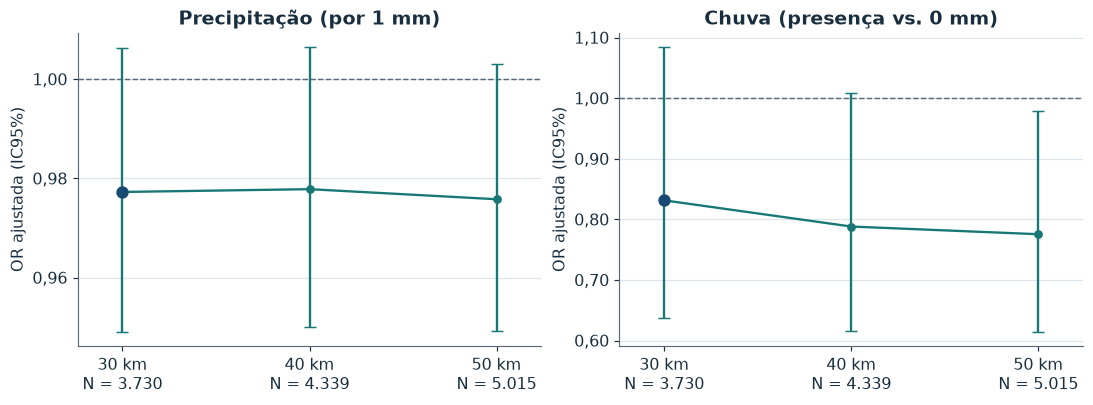

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(10.3, 3.75), layout="constrained")
for ax, (exposicao, titulo) in zip(eixos, exposicoes.items()):
    efeitos = sensibilidade.loc[sensibilidade["exposicao"].eq(exposicao)].sort_values("limite_km")
    x = efeitos["limite_km"]
    y = efeitos["odds_ratio"]
    ax.axhline(1, color=CINZA, linestyle="--", linewidth=1)
    ax.errorbar(
        x, y,
        yerr=[y - efeitos["ic_95_inf"], efeitos["ic_95_sup"] - y],
        fmt="o-", color=VERDE, capsize=4, linewidth=1.6, markersize=5,
    )
    principal = efeitos["limite_km"].eq(LIMITE_DISTANCIA_KM)
    ax.scatter(x[principal], y[principal], color=AZUL, s=56, zorder=4)
    ax.set_xticks(x, [
        f"{inteiro(limite)} km\nN = {inteiro(n)}"
        for limite, n in zip(x, efeitos["n"])
    ])
    ax.set(title=titulo, ylabel="OR ajustada (IC95%)")
    ax.yaxis.set_major_locator(MultipleLocator(0.02 if exposicao == "precipitacao_mm" else 0.1))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: decimal(valor, 2)))
    ax.grid(axis="y")
    ax.margins(x=0.12)

plt.show()

As estimativas por 1 mm ficaram próximas entre os três cenários, com intervalos que incluem 1. Para a variável binária, a estimativa se afastou de 1 e, a 50 km, o IC95% ficou abaixo de 1. As amostras são aninhadas e mudam quando se amplia o limite. Essa variação informa sobre a sensibilidade do resultado ao critério espacial. A interpretação principal segue o limite predefinido de 30 km.

## 7. Diagnósticos e análise complementar

### Ausência de precipitação

As comparações vêm do modelo de ausência do pipeline, ajustado por gravidade, ano, mês, distância, condição meteorológica da PRF e estação do INMET. A referência para gravidade é a categoria com vítimas fatais.

In [9]:
comparacoes_ausencia = ausencia.loc[ausencia.index.str.startswith("C(classificacao_acidente)[T.")].copy()
comparacoes_ausencia["Gravidade"] = (
    comparacoes_ausencia.index.str.extract(r"\[T\.(.+)\]", expand=False)
    + " vs. Com Vítimas Fatais"
)
exibir_estimativas(comparacoes_ausencia, {"Gravidade": "Comparação"})

,Comparação,OR,IC95%,p
0,Com Vítimas Feridas vs. Com Vítimas Fatais,"0,7262","0,4672 a 1,1287","0,1551"
1,Sem Vítimas vs. Com Vítimas Fatais,"0,9276","0,5671 a 1,5173","0,7648"


Os dois intervalos do contraste de gravidade incluem 1. A análise por casos completos ainda pode estar sujeita a seleção por fatores não avaliados.

### Regressão logística multinomial complementar

O modelo apresenta contrastes específicos para vítimas feridas e fatais, usando acidentes sem vítimas como referência.

In [10]:
efeitos_multinomiais = multinomial.assign(
    Exposição=multinomial["variavel"].map(exposicoes),
)
exibir_estimativas(efeitos_multinomiais, {"Exposição": "Exposição", "comparacao": "Comparação"})

,Exposição,Comparação,OR,IC95%,p
0,Precipitação (por 1 mm),Com Vítimas Feridas vs Sem Vítimas,"0,9731","0,9442 a 1,0028","0,0754"
1,Precipitação (por 1 mm),Com Vítimas Fatais vs Sem Vítimas,"0,9888","0,9243 a 1,0579","0,7438"
2,Chuva (presença vs. 0 mm),Com Vítimas Feridas vs Sem Vítimas,"0,8990","0,6715 a 1,2035","0,4742"
3,Chuva (presença vs. 0 mm),Com Vítimas Fatais vs Sem Vítimas,"0,5544","0,2651 a 1,1590","0,1169"


Os quatro intervalos incluem 1. Os contrastes envolvendo vítimas fatais são menos precisos que os correspondentes a vítimas feridas.

### Chances proporcionais

O pipeline apresenta no console uma comparação exploratória dos coeficientes em dois cortes cumulativos. Essa comparação ajuda a verificar se a direção e a magnitude estimadas variam entre os cortes. Um teste formal de Brant exigiria um procedimento separado.

## 8. Síntese

Na amostra principal de até 30 km, os modelos ajustados não forneceram evidência estatisticamente significativa de associação entre precipitação e gravidade. A análise de sensibilidade mostrou estimativas semelhantes para a exposição contínua e maior variação para a presença de chuva.

A precipitação é uma medida da estação pareada, sujeita à distância e à diferença de horário em relação ao acidente. Casos sem medição não entram nos modelos ordinais. Como a base reúne acidentes registrados, os resultados descrevem a gravidade entre essas ocorrências. O risco de ocorrer um acidente exigiria dados de exposição ao tráfego.